# MiMo-V2.6's RL loss, by hand

Companion notebook for [lesson 4](README.md). It recomputes every worked example from [Part 2](02_rl_algorithm.md) and [Part 5](05_distillation.md) on toy numbers, so you can change them and see what moves.

1. Group advantages and dynamic sampling
2. Loss aggregation: per-sequence mean, token-mean, prompt-mean
3. The importance ratio: why reweighting recovers the right gradient
4. Clipping is a mask: a finite-difference check
5. Reward shaping: GAR and the length penalty
6. Segment penalties that conserve advantage mass
7. On-policy distillation: GRPO with the teacher as the advantage

Runs on CPU in a few seconds. Needs only `numpy` and `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## 1. Group advantages and dynamic sampling

GRPO samples a group of G attempts per prompt and uses the group mean as the baseline. The 2024 recipe also divided by the group's standard deviation; MiMo does not (`norm_adv_by_std_in_grpo: false`). Below are three groups of 16 with binary rewards.

In [2]:
groups = {
    "15 of 16 pass": np.array([1]*15 + [0]*1, float),
    " 8 of 16 pass": np.array([1]*8 + [0]*8, float),
    " 0 of 16 pass": np.array([0]*16, float),
}
for name, R in groups.items():
    a_mean = R - R.mean()
    a_std = a_mean / (R.std() + 1e-6)
    print(f"{name}:  mean-only A(pass, fail) = {a_mean.max():+.3f}, {a_mean.min():+.3f}  sum|A| = {np.abs(a_mean).sum():.2f}"
          f"   |  std-normalized = {a_std.max():+.3f}, {a_std.min():+.3f}  sum|A| = {np.abs(a_std).sum():.2f}")

15 of 16 pass:  mean-only A(pass, fail) = +0.062, -0.938  sum|A| = 1.88   |  std-normalized = +0.258, -3.873  sum|A| = 7.75
 8 of 16 pass:  mean-only A(pass, fail) = +0.500, -0.500  sum|A| = 8.00   |  std-normalized = +1.000, -1.000  sum|A| = 16.00
 0 of 16 pass:  mean-only A(pass, fail) = +0.000, +0.000  sum|A| = 0.00   |  std-normalized = +0.000, +0.000  sum|A| = 0.00


With std normalization the lone failure in the 15/16 group gets an advantage of −3.9, larger in magnitude than anything in the balanced 8/16 group. The group's total |A| roughly quadruples (1.9 → 7.7) while the balanced group's only doubles (8 → 16), so near-unanimous groups are up-weighted relative to balanced ones. Mean-only advantages keep every group on the same scale.

The 0/16 group has zero advantage everywhere: it carries no gradient. **Dynamic sampling** drops such groups (and all-pass groups) before the batch is built.

In [3]:
def keep_group(R, infra_failed=None):
    # mirrors the released sampler: ignore infra failures; <=1 valid rollout counts as no signal
    valid = R if infra_failed is None else R[~infra_failed]
    return len(valid) > 1 and valid.std() > 0

for name, R in groups.items():
    print(f"{name}: keep = {keep_group(R)}")

# infra failures: replaced by the mean of valid scores for the baseline, then given exactly zero advantage
R = np.array([1, 1, 0, 0, 0, 1, 0, 0], float)
infra = np.array([0, 0, 0, 1, 0, 0, 1, 0], bool)
R_fill = R.copy(); R_fill[infra] = R[~infra].mean()
A = R_fill - R_fill.mean(); A[infra] = 0.0
print("\nadvantages with two infra failures (rows 3 and 6):", A)

15 of 16 pass: keep = True
 8 of 16 pass: keep = True
 0 of 16 pass: keep = False

advantages with two infra failures (rows 3 and 6): [ 0.5  0.5 -0.5  0.  -0.5  0.5  0.  -0.5]


## 2. Loss aggregation

Every token gets the per-token term ℓ = r·M·A·log π. The aggregation rule sets each token's weight. This cell implements the three rules and the released `compute_prompt_loss_weights` (NumPy port).

In [4]:
def weights_seq_mean(lengths):
    N = len(lengths)
    return np.array([1.0 / (N * L) for L in lengths])

def weights_token_mean(lengths):
    return np.full(len(lengths), 1.0 / sum(lengths))

def compute_prompt_loss_weights(lengths, prompt_ids):
    # port of verl/trainer/ppo/core_algos.py::compute_prompt_loss_weights (XiaomiMiMo/verl, mimo-oss)
    totals = defaultdict(int)
    for pid, L in zip(prompt_ids, lengths):
        totals[pid] += L
    P = sum(t > 0 for t in totals.values())
    return np.array([1.0 / (P * totals[pid]) if L else 0.0 for pid, L in zip(prompt_ids, lengths)])

# the worked example: A succeeds in 1,000 tokens (adv +0.5), B fails in 9,000 tokens (adv -0.5)
lengths = [1000, 9000]; adv = np.array([0.5, -0.5]); pids = ["q", "q"]
for name, w in [("per-sequence mean", weights_seq_mean(lengths)),
                ("prompt-mean", compute_prompt_loss_weights(lengths, pids))]:
    per_token = w * adv
    total = per_token * np.array(lengths)
    print(f"{name:18s} push per token A={per_token[0]:+.2e} B={per_token[1]:+.2e}   total A={total[0]:+.3f} B={total[1]:+.3f}")

per-sequence mean  push per token A=+2.50e-04 B=-2.78e-05   total A=+0.250 B=-0.250
prompt-mean        push per token A=+5.00e-05 B=-5.00e-05   total A=+0.050 B=-0.450


Per-sequence mean pushes each of B's tokens nine times more weakly than A's. Long failures are cheap, so failing trajectories drift longer. Prompt-mean pushes every token in the group equally.

Across prompts, token-mean lets the prompt with the longest rollouts own the update; prompt-mean gives every prompt the same share:

In [5]:
lengths = [2_000]*16 + [60_000]*16
pids = ["short"]*16 + ["long"]*16
for name, w in [("token-mean", weights_token_mean(lengths)), ("prompt-mean", compute_prompt_loss_weights(lengths, pids))]:
    share_short = (w[:16] * np.array(lengths[:16])).sum()
    print(f"{name:12s} share of gradient: short prompt {share_short:.1%}, long prompt {1-share_short:.1%}")

token-mean   share of gradient: short prompt 3.2%, long prompt 96.8%
prompt-mean  share of gradient: short prompt 50.0%, long prompt 50.0%


## 3. The importance ratio

Take a one-step "policy": a softmax over 5 tokens with logits θ. Each token has a fixed reward. The objective is J(θ) = E_{y~π_θ}[R(y)], and its exact gradient is available in closed form.

The data, however, was sampled from a **stale** policy μ (older logits). We compare two estimates from μ's samples:

- naive: average of A·∇log π_θ(y)
- corrected: average of (π_θ(y)/μ(y))·A·∇log π_θ(y)

In [6]:
def softmax(z):
    z = z - z.max(); e = np.exp(z); return e / e.sum()

def grad_logp(theta, y):
    # d/dtheta log softmax(theta)[y] = onehot(y) - softmax(theta)
    g = -softmax(theta); g[y] += 1.0; return g

R_tok = np.array([1.0, 0.0, 0.0, 0.5, 0.0])     # token 0 is the "right answer"
theta_old = np.array([0.0, 1.5, 0.5, 0.0, 0.0])  # the sampler's (stale) logits
theta = np.array([1.0, 0.2, 0.5, 0.3, 0.0])      # the current policy, after a few updates
pi, mu = softmax(theta), softmax(theta_old)

# exact gradient of J = sum_y pi(y) R(y)
true_grad = sum(pi[y] * R_tok[y] * grad_logp(theta, y) for y in range(5))

n = 200_000
ys = rng.choice(5, size=n, p=mu)
b = (pi * R_tok).sum()                      # baseline: current expected reward (any constant works)
A = R_tok[ys] - b
G = np.stack([grad_logp(theta, y) for y in range(5)])[ys]
naive = (A[:, None] * G).mean(0)
r = pi[ys] / mu[ys]
corrected = ((r * A)[:, None] * G).mean(0)

cos = lambda u, v: u @ v / np.linalg.norm(u) / np.linalg.norm(v)
print("pi (current):", pi); print("mu (sampler):", mu)
print("\ntrue gradient     :", true_grad)
print("naive estimate    :", naive, f"  cos = {cos(naive, true_grad):.3f}")
print("ratio-corrected   :", corrected, f"  cos = {cos(corrected, true_grad):.3f}")

pi (current): [0.3424 0.1539 0.2077 0.17   0.126 ]
mu (sampler): [0.1095 0.4909 0.1806 0.1095 0.1095]

true gradient     : [ 0.1961 -0.0658 -0.0888  0.0123 -0.0538]
naive estimate    : [ 0.1532 -0.1694 -0.0231  0.0525 -0.0131]   cos = 0.816
ratio-corrected   : [ 0.1973 -0.0661 -0.0897  0.0119 -0.0534]   cos = 1.000


The naive estimate optimizes for the sampler's habits: it points in a noticeably different direction. Multiplying by r = π/μ recovers the true gradient (cosine ≈ 1). Note that r says nothing about whether a token is good; the advantage A sets the direction, and r only fixes how often each token appears in the data.

The large ratios are where variance comes from. Look at the spread of r:

In [7]:
for y in range(5):
    print(f"token {y}: mu={mu[y]:.3f} pi={pi[y]:.3f}  r={pi[y]/mu[y]:.2f}")

token 0: mu=0.110 pi=0.342  r=3.13
token 1: mu=0.491 pi=0.154  r=0.31
token 2: mu=0.181 pi=0.208  r=1.15
token 3: mu=0.110 pi=0.170  r=1.55
token 4: mu=0.110 pi=0.126  r=1.15


## 4. Clipping is a mask

GRPO's clipped per-token objective is J = min(r·A, clip(r, 1−ε, 1+ε)·A) with r = π_θ(y)/μ(y). Its gradient should equal M·r·A·∇log π_θ(y), where M = 0 when the token is clipped. Check this numerically with finite differences for several (r, A) cases.

In [8]:
def clipped_obj(theta, y, mu_y, A, eps=0.2):
    r = softmax(theta)[y] / mu_y
    return min(r * A, np.clip(r, 1 - eps, 1 + eps) * A)

def fd_grad(f, theta, h=1e-6):
    g = np.zeros_like(theta)
    for k in range(len(theta)):
        e = np.zeros_like(theta); e[k] = h
        g[k] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g

def mask_grad(theta, y, mu_y, A, eps=0.2):
    r = softmax(theta)[y] / mu_y
    clipped = (A > 0 and r > 1 + eps) or (A < 0 and r < 1 - eps)
    M = 0.0 if clipped else 1.0
    return M * r * A * grad_logp(theta, y), M, r

theta = np.array([0.4, 0.0, -0.3, 0.2, 0.1]); y = 0; p_y = softmax(theta)[y]
for mu_y, A in [(p_y / 1.05, +1.0), (p_y / 1.6, +1.0), (p_y / 0.95, -1.0), (p_y / 0.5, -1.0), (p_y / 0.5, +1.0)]:
    g_fd = fd_grad(lambda t: clipped_obj(t, y, mu_y, A), theta)
    g_m, M, r = mask_grad(theta, y, mu_y, A)
    print(f"r={r:4.2f} A={A:+.0f}  M={M:.0f}   max|fd - mask form| = {np.abs(g_fd - g_m).max():.1e}")

r=1.05 A=+1  M=1   max|fd - mask form| = 1.3e-10
r=1.60 A=+1  M=0   max|fd - mask form| = 0.0e+00
r=0.95 A=-1  M=1   max|fd - mask form| = 8.7e-11
r=0.50 A=-1  M=0   max|fd - mask form| = 0.0e+00
r=0.50 A=+1  M=1   max|fd - mask form| = 4.1e-11


The two gradients agree to finite-difference precision in every case. Clipping never rescales a token's update; it turns it off. That is why MiMo's Eq. 1 can write the loss as sg(r)·M·A·log π with the clipping folded into M.

MiMo uses **four** bounds, two per advantage sign, and tunes them with policy entropy. Here is the mask, with illustrative bounds:

In [9]:
def four_bound_mask(r, A, pos=(0.5, 3.0), neg=(0.6, 2.0)):
    lo, hi = pos if A > 0 else neg
    return float(lo <= r <= hi) if A != 0 else 0.0

def grpo_mask(r, A, eps=0.2):
    if A > 0: return float(r <= 1 + eps)
    if A < 0: return float(r >= 1 - eps)
    return 0.0

print(" r     A  | GRPO one-sided | four bounds")
for r_ in [0.1, 0.7, 1.0, 1.3, 4.0, 10.0]:
    for A_ in [+1, -1]:
        print(f"{r_:5.1f} {A_:+d}  |       {grpo_mask(r_, A_):.0f}        |      {four_bound_mask(r_, A_):.0f}")

 r     A  | GRPO one-sided | four bounds
  0.1 +1  |       1        |      0
  0.1 -1  |       0        |      0
  0.7 +1  |       1        |      1
  0.7 -1  |       0        |      1
  1.0 +1  |       1        |      1
  1.0 -1  |       1        |      1
  1.3 +1  |       0        |      1
  1.3 -1  |       1        |      1
  4.0 +1  |       0        |      0
  4.0 -1  |       1        |      0
 10.0 +1  |       0        |      0
 10.0 -1  |       1        |      0


The four-bound mask additionally drops good tokens whose ratio has collapsed (r = 0.1, A > 0) and bad tokens whose ratio has exploded (r = 4 or 10, A < 0). These are the most off-policy, highest-variance terms. The bounds above are made up; the report gives only the initial values [0.2, 5.0] and says they are tuned by entropy.

## 5. Reward shaping: GAR and the length penalty

**GAR** (Groupwise Advantage Redistribution) rescales the advantages of passing rollouts by grader quality factors f ∈ (0, 1], keeping their total fixed:

λ = Σ_{passing} A / Σ_{passing} f·A,  A'_i = λ·f_i·A_i for passing rollouts.

In [10]:
def gar(R, f, cap=2.0):
    A = R - R.mean()
    P = R == 1
    lam = A[P].sum() / (f[P] * A[P]).sum()
    lam = min(lam, cap)
    A2 = A.copy(); A2[P] = lam * f[P] * A[P]
    return A, A2 - A2.mean(), lam

R = np.array([1]*6 + [0]*10, float)
f = np.array([1.0, 0.9, 0.75, 0.6, 0.45, 0.3] + [1.0]*10)
A, A2, lam = gar(R, f)
print("lambda =", round(lam, 3))
print("before:", A[:7]); print("after: ", A2[:7])
print("positive mass before/after:", A[R==1].sum(), A2[R==1].sum())
print("with cap=1.2:", gar(R, f, cap=1.2)[1][:7], " <- capped: mass shrinks, then re-centering shifts every row")

lambda = 1.5
before: [ 0.625  0.625  0.625  0.625  0.625  0.625 -0.375]
after:  [ 0.9375  0.8438  0.7031  0.5625  0.4219  0.2812 -0.375 ]
positive mass before/after: 3.75 3.75
with cap=1.2: [ 0.7969  0.7219  0.6094  0.4969  0.3844  0.2719 -0.3281]  <- capped: mass shrinks, then re-centering shifts every row


**Length penalty** on successes, with the values of the fork's reference penalty profile (`recipes/arvo/REFERENCE_PENALTIES.json`: `max_penalty` X = 0.2, dead zone δ = 0, saturation s = 1, exponent γ = 1.5, reference = 30th percentile of successful lengths). The profile is off by default in every released launcher. The second column shows a variant with a 30% dead zone.

In [11]:
def length_penalty(ratio, X=0.2, delta=0.0, s=1.0, gamma=1.5):
    t = np.clip((ratio - 1 - delta) / (s - delta), 0, 1)
    return X * t ** gamma

for ratio in [0.8, 1.0, 1.3, 1.5, 1.75, 2.0, 3.0]:
    print(f"length = {ratio:4.2f} x reference  ->  reward reduced by {length_penalty(ratio):.4f}"
          f"   (with a 0.3 dead zone: {length_penalty(ratio, delta=0.3):.4f})")

length = 0.80 x reference  ->  reward reduced by 0.0000   (with a 0.3 dead zone: 0.0000)
length = 1.00 x reference  ->  reward reduced by 0.0000   (with a 0.3 dead zone: 0.0000)
length = 1.30 x reference  ->  reward reduced by 0.0329   (with a 0.3 dead zone: 0.0000)
length = 1.50 x reference  ->  reward reduced by 0.0707   (with a 0.3 dead zone: 0.0305)
length = 1.75 x reference  ->  reward reduced by 0.1299   (with a 0.3 dead zone: 0.1031)
length = 2.00 x reference  ->  reward reduced by 0.2000   (with a 0.3 dead zone: 0.2000)
length = 3.00 x reference  ->  reward reduced by 0.2000   (with a 0.3 dead zone: 0.2000)


## 6. Segment penalties that conserve advantage mass

Flag a few tokens (malformed tool calls, say). In positive trajectories they are masked and their mass is handed to the clean positive tokens (factor α). In negative trajectories they are pushed κ times harder, and the extra mass is taken back from the clean negative tokens (factor β).

In [12]:
def signed_rebalance(A_tok, flagged, kappa=2.0, alpha_max=2.0, beta_min=0.5):   # reference-profile values
    pos, neg = A_tok > 0, A_tok < 0
    removed = A_tok[pos & flagged].sum();           pos_base = A_tok[pos & ~flagged].sum()
    added = ((kappa - 1) * np.abs(A_tok[neg & flagged])).sum(); neg_base = np.abs(A_tok[neg & ~flagged]).sum()
    alpha = min(alpha_max, 1 + removed / pos_base)
    beta = max(beta_min, 1 - added / neg_base)
    out = A_tok.copy()
    out[pos & flagged] = 0.0;  out[pos & ~flagged] *= alpha
    out[neg & flagged] *= kappa; out[neg & ~flagged] *= beta
    return out, alpha, beta

# 2 trajectories x 6 tokens, flattened: one positive (A=+0.5), one negative (A=-0.5)
A_tok = np.array([0.5]*6 + [-0.5]*6)
flagged = np.array([0, 0, 1, 0, 0, 0,   0, 1, 1, 0, 0, 0], bool)
out, alpha, beta = signed_rebalance(A_tok, flagged)
print("alpha =", round(alpha, 3), " beta =", round(beta, 3))
print("before:", A_tok); print("after: ", np.round(out, 3))
print("positive mass", A_tok[A_tok>0].sum(), "->", out[out>0].sum(), "| negative mass", A_tok[A_tok<0].sum(), "->", out[out<0].sum())

alpha = 1.2  beta = 0.5
before: [ 0.5  0.5  0.5  0.5  0.5  0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]
after:  [ 0.6   0.6   0.    0.6   0.6   0.6  -0.25 -1.   -1.   -0.25 -0.25 -0.25]
positive mass 3.0 -> 3.0 | negative mass -3.0 -> -3.0


## 7. On-policy distillation: GRPO with the teacher as the advantage

On-policy distillation keeps the same machinery and swaps the advantage. The student samples a token; the teacher scores it; the per-token advantage is

A_t = sg[ log π_teacher(y_t) − log π_student(y_t) ].

The expected value of −A_t under the student's own samples is the reverse KL(student ‖ teacher). Below, a categorical student is pulled toward a bimodal teacher with the sampled-token estimator only: no reward, no verifier.

reverse KL: start 0.974 -> end 0.0000
teacher top-3: [0.461 0.309 0.023]  student top-3: [0.461 0.309 0.023]


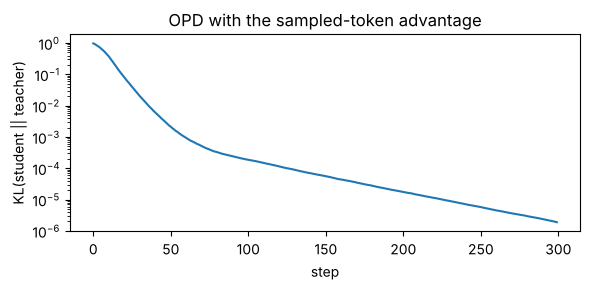

In [13]:
V = 12
teacher = softmax(np.array([3.0, 2.6] + [0.0]*(V - 2)))   # two strong modes
theta_s = rng.normal(0, 0.5, V)                             # student logits
lr, batch, steps = 0.5, 256, 300
kl_hist = []
for step in range(steps):
    p = softmax(theta_s)
    kl_hist.append((p * (np.log(p) - np.log(teacher))).sum())    # reverse KL(student || teacher)
    ys = rng.choice(V, size=batch, p=p)                          # on-policy samples
    A = np.log(teacher[ys]) - np.log(p[ys])                      # per-token advantage, stop-gradient
    A = A - A.mean()                                             # a baseline lowers variance; the expectation is unchanged
    g = np.zeros(V)
    for y, a in zip(ys, A):
        g += a * grad_logp(theta_s, y)
    theta_s += lr * g / batch                                    # gradient ascent on E[A * log pi]

p = softmax(theta_s)
print("reverse KL: start %.3f -> end %.4f" % (kl_hist[0], kl_hist[-1]))
print("teacher top-3:", np.round(teacher[:3], 3), " student top-3:", np.round(p[:3], 3))
plt.figure(figsize=(6, 3)); plt.plot(kl_hist); plt.yscale("log")
plt.xlabel("step"); plt.ylabel("KL(student || teacher)"); plt.title("OPD with the sampled-token advantage"); plt.tight_layout(); plt.show()

Things to try:

- Replace the student's full softmax with a restricted family (for example, only one free logit plus a shared rest). Reverse KL then commits to one of the teacher's modes ("mode-seeking"), where forward KL (SFT on teacher samples) would spread across both.
- In section 3, move `theta_old` further from `theta` and watch the variance of the corrected estimate grow, then add a truncation `np.minimum(r, 5)` and see the bias it introduces.
- In section 2, add a third prompt with very long rollouts and compare token-mean and prompt-mean shares.